# Six-city prediction-market calibration study

**Real historical Kalshi quotes and finalized outcomes · January 1–October 7, 2026**

This expands the original 401-contract, Chicago-only pilot to six daily-high temperature series. The goal is to test robustness across geography and seasons without selecting cities, dates or model settings based on profitability.

Start with **Run → Run All Cells** from this extracted folder. Analysis uses the included data and does not require API access. A copy of every collected response is included in `raw/`.

The clock remains 24 hours before the **recorded exchange close**, which may already be during the weather day. Historical schedule versions and executable fills are not verified.

In [1]:
from pathlib import Path
import io, contextlib
import pandas as pd
from IPython.display import display, Image
from expanded_analysis import analyze

with contextlib.redirect_stdout(io.StringIO()):
    df, tables, predictions, trades, equity, summary = analyze()
OUT = Path('outputs/real')
print(f"{len(df):,} accepted real contracts; {df.city.nunique()} cities; "
      f"{df.weather_date.nunique()} calendar weather dates; {df.event_id.nunique():,} city-date events")
print('Weather date range:', df.weather_date.min(), 'through', df.weather_date.max())
display(df[['city','market_id','weather_date','quote_time','entry_time','price','outcome']].head())

10,051 accepted real contracts; 6 cities; 280 calendar weather dates; 1,680 city-date events
Weather date range: 2026-01-01 through 2026-10-07


,city,market_id,weather_date,quote_time,entry_time,price,outcome
0,Miami,KXHIGHMIA-26JAN01-B67.5,2026-01-01,2026-01-01 04:59:00+00:00,2026-01-01 04:59:00+00:00,0.465,1
1,Miami,KXHIGHMIA-26JAN01-B69.5,2026-01-01,2026-01-01 04:59:00+00:00,2026-01-01 04:59:00+00:00,0.425,0
2,Miami,KXHIGHMIA-26JAN01-B71.5,2026-01-01,2026-01-01 04:59:00+00:00,2026-01-01 04:59:00+00:00,0.105,0
3,Miami,KXHIGHMIA-26JAN01-B73.5,2026-01-01,2026-01-01 04:57:00+00:00,2026-01-01 04:59:00+00:00,0.025,0
4,Miami,KXHIGHMIA-26JAN01-T67,2026-01-01,2026-01-01 04:59:00+00:00,2026-01-01 04:59:00+00:00,0.045,0


## Breadth and missing data

A contract is a temperature bucket, not an independent weather realization. City-date events count different city/day combinations. Calendar weather dates count days once across all cities and are the main clustering unit.

The collector retains exclusions and monthly coverage. Missing or invalid quotes are excluded, never filled using settlement prices. Partial events remain in the contract-level analysis and are identifiable in `event_completeness.csv`. This does not establish that missingness is random.

,city,contracts,weather_dates,first_date,last_date,median_spread
0,Austin,1668,280,2026-01-01,2026-10-07,0.01
1,Chicago,1679,280,2026-01-01,2026-10-07,0.01
2,Denver,1674,280,2026-01-01,2026-10-07,0.01
3,Los Angeles,1676,280,2026-01-01,2026-10-07,0.01
4,Miami,1674,280,2026-01-01,2026-10-07,0.01
5,New York City,1680,280,2026-01-01,2026-10-07,0.01


,city,median_full_spread,p95_full_spread,max_full_spread,median_quote_age_minutes,max_quote_age_minutes
0,Austin,0.01,0.05,0.12,0.0,114.0
1,Chicago,0.01,0.04,0.12,0.0,96.0
2,Denver,0.01,0.05,0.12,0.0,120.0
3,Los Angeles,0.01,0.04,0.26,0.0,120.0
4,Miami,0.01,0.04,0.13,0.0,106.0
5,New York City,0.01,0.04,0.14,0.0,60.0


,excluded_contracts
error,
No valid recent bid/ask candle,27
Not finalized binary,2


,weather_date,National Weather Service,The Weather Company
0,2026-01,1116,0
1,2026-02,1005,0
2,2026-03,1116,0
3,2026-04,1078,0
4,2026-05,1107,0
5,2026-06,1073,0
6,2026-07,1113,0
7,2026-08,468,645
8,2026-09,0,1078
9,2026-10,0,252


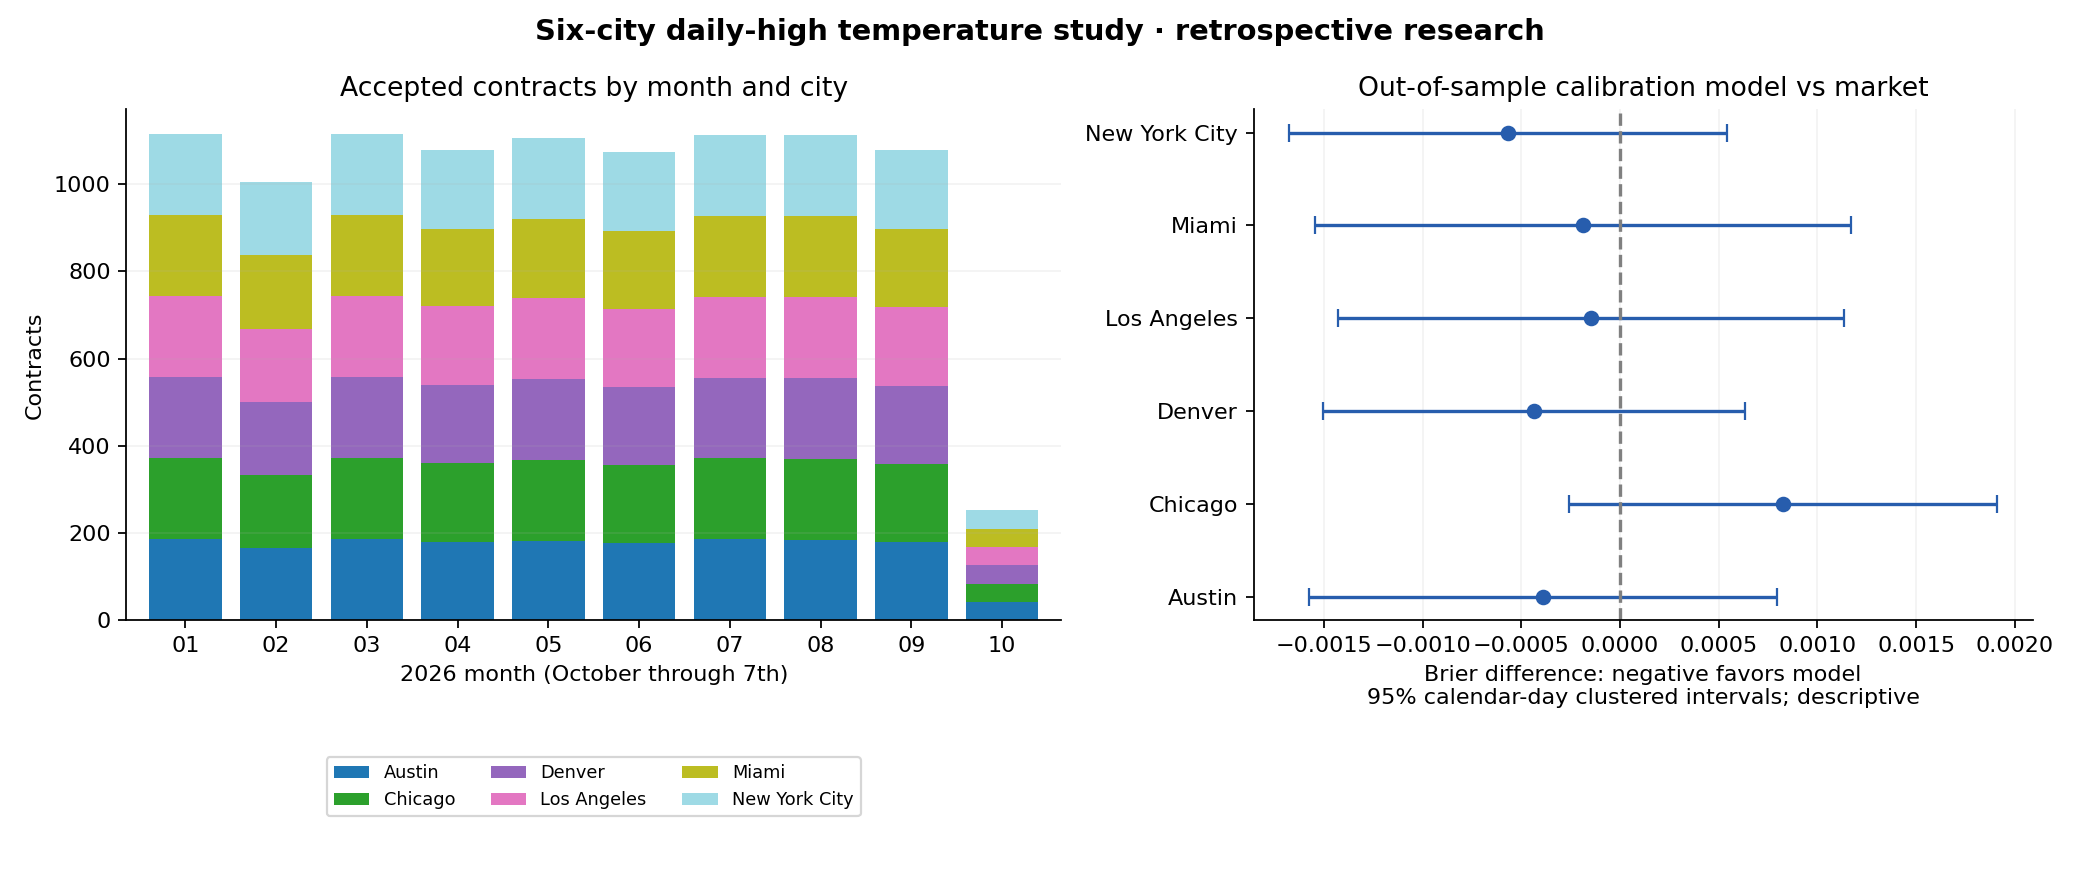

In [2]:
display(pd.read_csv(OUT/'coverage_by_city.csv'))
display(pd.read_csv(OUT/'quote_quality_by_city.csv'))
display(pd.read_csv('failures.csv').groupby('error').size().rename('excluded_contracts').to_frame())
display(pd.read_csv(OUT/'settlement_source_by_month.csv'))
display(Image(filename=str(OUT/'sample_expansion.png')))

## Unchanged forecasting and sizing method

The model is logistic calibration of the market log-odds, with C=1.0, at least 150 prior finalized contracts and 30-day refits. It pools the six cities within Kalshi. Each test block uses only earlier available labels, excluding events in that block. No city-specific parameters are optimized.

The original quarter-Kelly policy and cost scenarios are unchanged: a two-cent full spread and half-cent fee per contract, $10,000 starting cash, 2% position cap, 4% city-event cap and 50% gross locked-capital cap. Cross-city weather exposure is still correlated; the event cap is not a global weather-day cap.

Out-of-sample means each historical prediction uses only eligible earlier labels. It does not mean this entire research process was prospectively preregistered: the earlier Chicago sample had already been inspected.

In [3]:
display(pd.read_csv(OUT/'training_windows.csv'))
display(tables['out_of_sample_brier'])
print('OOS weather dates:', predictions.weather_date.nunique())
print('OOS city-date events:', predictions.event_id.nunique())
print('OOS entry range:', predictions.entry_time.min(), 'through', predictions.entry_time.max())

OOS weather dates: 250
OOS city-date events: 1500
OOS entry range: 2026-01-31 04:59:00+00:00 through 2026-10-07 08:00:00+00:00


,block,first_entry,last_entry,test_contracts,training_contracts,latest_training_label,intercept,slope
0,1,2026-01-31 04:59:00+00:00,2026-03-01 07:59:00+00:00,1077,1044,2026-01-30 13:02:16.909351+00:00,0.185913,1.263830
1,2,2026-03-02 04:59:00+00:00,2026-03-31 07:59:00+00:00,1080,2121,2026-03-01 13:02:06.840986+00:00,0.214540,1.274108
2,3,2026-04-01 04:59:00+00:00,2026-04-30 07:59:00+00:00,1078,3201,2026-03-31 12:01:58.027230+00:00,0.220615,1.267326
3,4,2026-05-01 04:59:00+00:00,2026-05-30 07:59:00+00:00,1071,4279,2026-04-30 12:02:47.712475+00:00,0.226881,1.269375
4,5,2026-05-31 04:59:00+00:00,2026-06-29 07:59:00+00:00,1073,5350,2026-05-30 12:02:10.624974+00:00,0.233796,1.281864
5,6,2026-06-30 04:59:00+00:00,2026-07-29 07:59:00+00:00,1077,6423,2026-06-29 12:01:12.762944+00:00,0.189980,1.243943
6,7,2026-07-30 04:59:00+00:00,2026-08-28 08:00:00+00:00,1080,7500,2026-07-29 12:01:06.023125+00:00,0.182091,1.242940
7,8,2026-08-29 05:00:00+00:00,2026-09-27 08:00:00+00:00,1075,8580,2026-08-28 14:12:35.713167+00:00,0.172524,1.238344
8,9,2026-09-28 05:00:00+00:00,2026-10-07 08:00:00+00:00,360,9655,2026-09-27 14:20:56.460376+00:00,0.156029,1.223952


,venue,n,n_events,mean_price,observed_rate,market_brier,constant_half_brier,model_brier,historical_base_brier
0,kalshi,8971,1500,0.173314,0.167094,0.101376,0.25,0.101227,0.139174


## Forecast quality and dependence checks

The Brier score averages squared probability error; lower is better. A **negative model-minus-market difference favors the calibration model**. Market and model scores use identical test contracts.

Calendar-day clusters combine related contracts across cities. Nonoverlapping seven-day clusters and moving-block bootstrap intervals of seven and fourteen days also assess nearby-date dependence. The bootstrap keeps every city's observations together within a sampled day, uses 2,000 replications and a fixed seed, and reports percentile intervals for the contract-weighted mean difference.

These methods do not remove nonstationarity, selection effects, or the need for more years of data. The per-city and per-month results below are descriptive; they are not a search for a profitable subgroup.

In [4]:
display(pd.read_csv(OUT/'dependence_checks.csv'))
display(pd.read_csv(OUT/'brier_by_city.csv'))
display(pd.read_csv(OUT/'brier_by_month.csv'))
display(pd.read_csv(OUT/'brier_by_settlement_source.csv'))
display(pd.read_csv(OUT/'geographic_cohorts.csv'))

,method,n_contracts,n_weather_dates,n_city_dates,model_minus_market_brier,se,ci_low,ci_high,p_value,n_clusters,block_days,repetitions,seed,n_calendar_days
0,Calendar-day clusters across cities,8971.0,250.0,1500.0,-0.000149,0.000250,-0.000641,0.000342,0.549962,250.0,NaN,NaN,NaN,NaN
1,Nonoverlapping 7-day clusters across cities,8971.0,250.0,1500.0,-0.000149,0.000281,-0.000719,0.000421,0.598103,36.0,NaN,NaN,NaN,NaN
2,7-day moving-block bootstrap,NaN,NaN,NaN,-0.000149,NaN,-0.000648,0.000378,NaN,NaN,7.0,2000.0,20261009.0,250.0
3,14-day moving-block bootstrap,NaN,NaN,NaN,-0.000149,NaN,-0.000636,0.000453,NaN,NaN,14.0,2000.0,20261009.0,250.0


,city,n,n_events,mean_price,observed_rate,market_brier,constant_half_brier,model_brier,historical_base_brier
0,Austin,1488,250,0.173679,0.168011,0.100634,0.25,0.100244,0.139785
1,Chicago,1499,250,0.171611,0.166778,0.111961,0.25,0.112788,0.138963
2,Denver,1494,250,0.173822,0.167336,0.106619,0.25,0.106183,0.139335
3,Los Angeles,1496,250,0.173877,0.167112,0.098603,0.25,0.098456,0.139186
4,Miami,1494,250,0.173367,0.166667,0.094839,0.25,0.094653,0.138889
5,New York City,1500,250,0.173533,0.166667,0.095591,0.25,0.095024,0.138889


,month,n,n_events,mean_price,observed_rate,market_brier,constant_half_brier,model_brier,historical_base_brier
0,2026-01,36,6,0.174167,0.166667,0.118331,0.25,0.120213,0.138889
1,2026-02,1005,168,0.172318,0.167164,0.102292,0.25,0.101610,0.139221
2,2026-03,1116,186,0.172164,0.166667,0.101273,0.25,0.100627,0.138889
3,2026-04,1078,180,0.172032,0.166048,0.105963,0.25,0.105689,0.138477
4,2026-05,1107,186,0.174697,0.168022,0.098706,0.25,0.097820,0.139792
5,2026-06,1073,180,0.174012,0.167754,0.104655,0.25,0.105586,0.139613
6,2026-07,1113,186,0.174438,0.167116,0.098560,0.25,0.098408,0.139188
7,2026-08,1113,186,0.173670,0.167116,0.098833,0.25,0.099352,0.139188
8,2026-09,1078,180,0.173404,0.166976,0.100903,0.25,0.101027,0.139095
9,2026-10,252,42,0.171766,0.166667,0.099611,0.25,0.098554,0.138889


,settlement_source,n,n_events,mean_price,observed_rate,market_brier,constant_half_brier,model_brier,historical_base_brier
0,National Weather Service,6996,1170,0.173220,0.167095,0.101172,0.25,0.100844,0.139175
1,The Weather Company,1975,330,0.173646,0.167089,0.102101,0.25,0.102584,0.139170


,cohort,n_contracts,n_weather_dates,n_city_dates,model_minus_market_brier,se,ci_low,ci_high,p_value,n_clusters
0,Chicago,1499,250,250,0.000827,0.000550,-0.000256,0.001911,0.133918,250
1,Five additional cities,7472,250,1250,-0.000345,0.000275,-0.000887,0.000197,0.210699,250


## Calibration pattern and illustrative trading result

The calibration figure is a full-sample descriptive chart. Calibration-bin inference now clusters all cities by weather date; `n_events` in these calibration tables denotes calendar-day clusters. P-values are suppressed below 30 clusters and Holm-adjusted within a table.

The portfolio holds to settlement and values open holdings at entry cost. Its equity, Sharpe and drawdown are **settlement-accounted**, not mark-to-market. Fixed-size and Kelly scenarios differ in exposure. No scenario is selected as a winner, and no return is claimed as executable.

Timing, opening-time and cash-conservation checks passed during analysis.


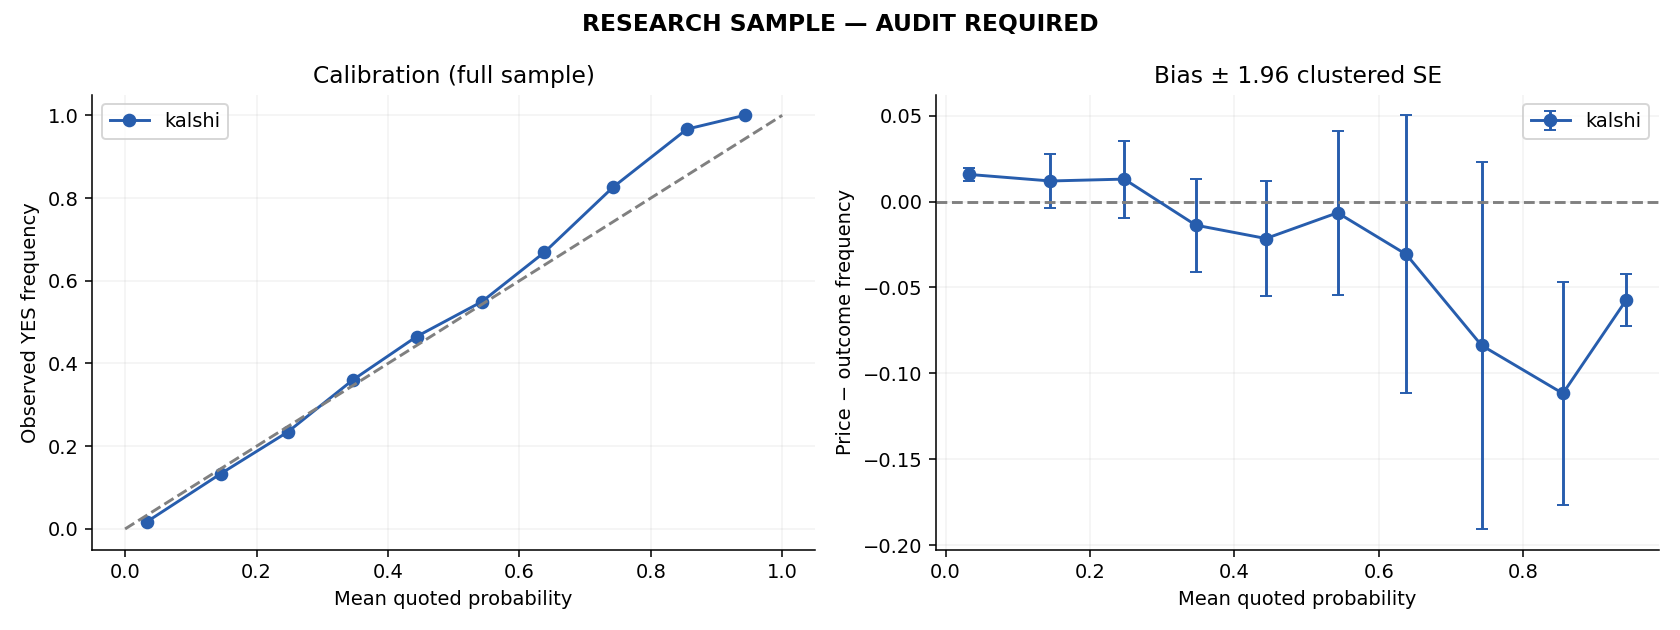

,venue,bin,n,n_events,mean_price,observed_rate,bias,se,ci_low,ci_high,p_value,sufficient_clusters,p_holm
0,kalshi,0,4486,250,0.031842,0.016942,0.014901,0.001960,0.011040,0.018761,5.929368e-13,True,4.743495e-12
1,kalshi,1,1248,250,0.145533,0.131410,0.014123,0.008718,-0.003048,0.031293,1.065141e-01,True,7.455985e-01
2,kalshi,2,1098,250,0.247395,0.234973,0.012423,0.012230,-0.011666,0.036511,3.107510e-01,True,1.000000e+00
3,kalshi,3,884,249,0.346601,0.361991,-0.015390,0.015253,-0.045432,0.014651,3.139532e-01,True,1.000000e+00
4,kalshi,4,665,234,0.443992,0.470677,-0.026684,0.017740,-0.061635,0.008267,1.338880e-01,True,8.033281e-01
5,kalshi,5,356,193,0.544326,0.544944,-0.000618,0.025206,-0.050334,0.049098,9.804654e-01,True,1.000000e+00
6,kalshi,6,154,117,0.638084,0.668831,-0.030747,0.041280,-0.112507,0.051014,4.578804e-01,True,1.000000e+00
7,kalshi,7,40,37,0.740500,0.800000,-0.059500,0.061330,-0.183883,0.064883,3.384378e-01,True,1.000000e+00
8,kalshi,8,26,25,0.855000,0.961538,-0.106538,0.038037,-0.185043,-0.028034,NaN,False,NaN
9,kalshi,9,14,14,0.938929,1.000000,-0.061071,0.009156,-0.080853,-0.041290,NaN,False,NaN


,kelly_fraction,full_spread,fee_per_contract,trades,ending_equity,total_return,settlement_max_drawdown,settlement_daily_sharpe
0,0.25,0.02,0.005,4418,13004.59,0.300459,-0.500054,0.90993


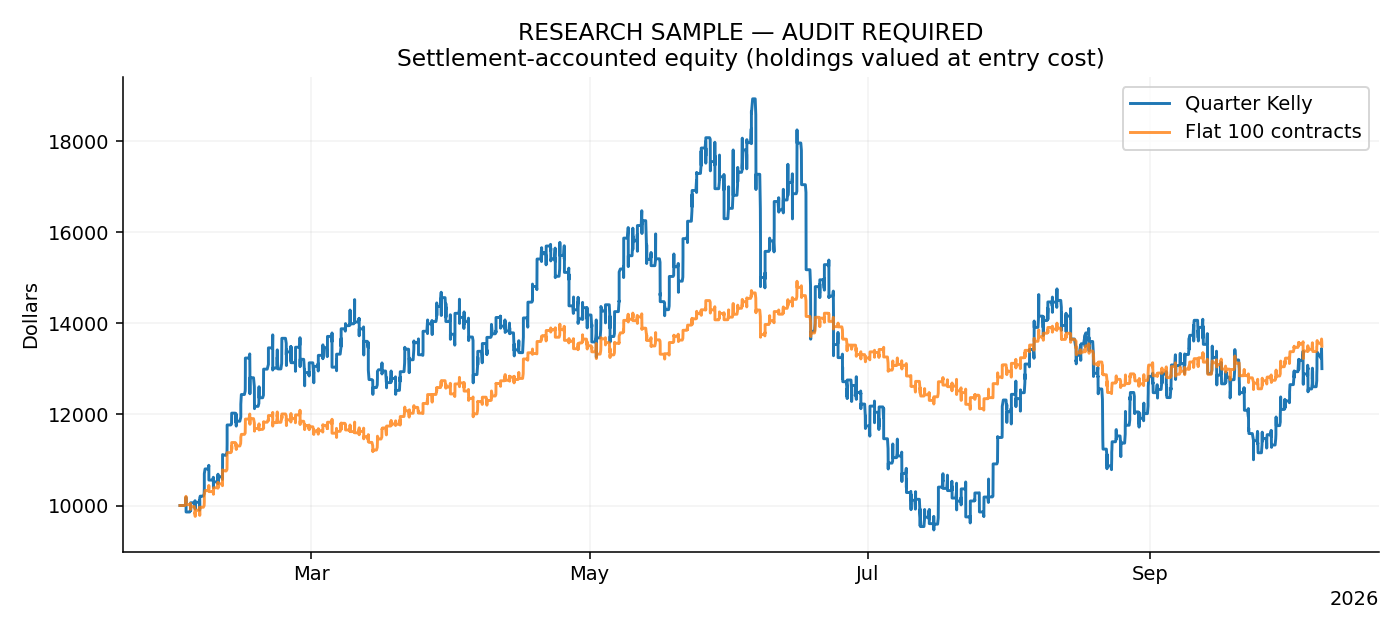

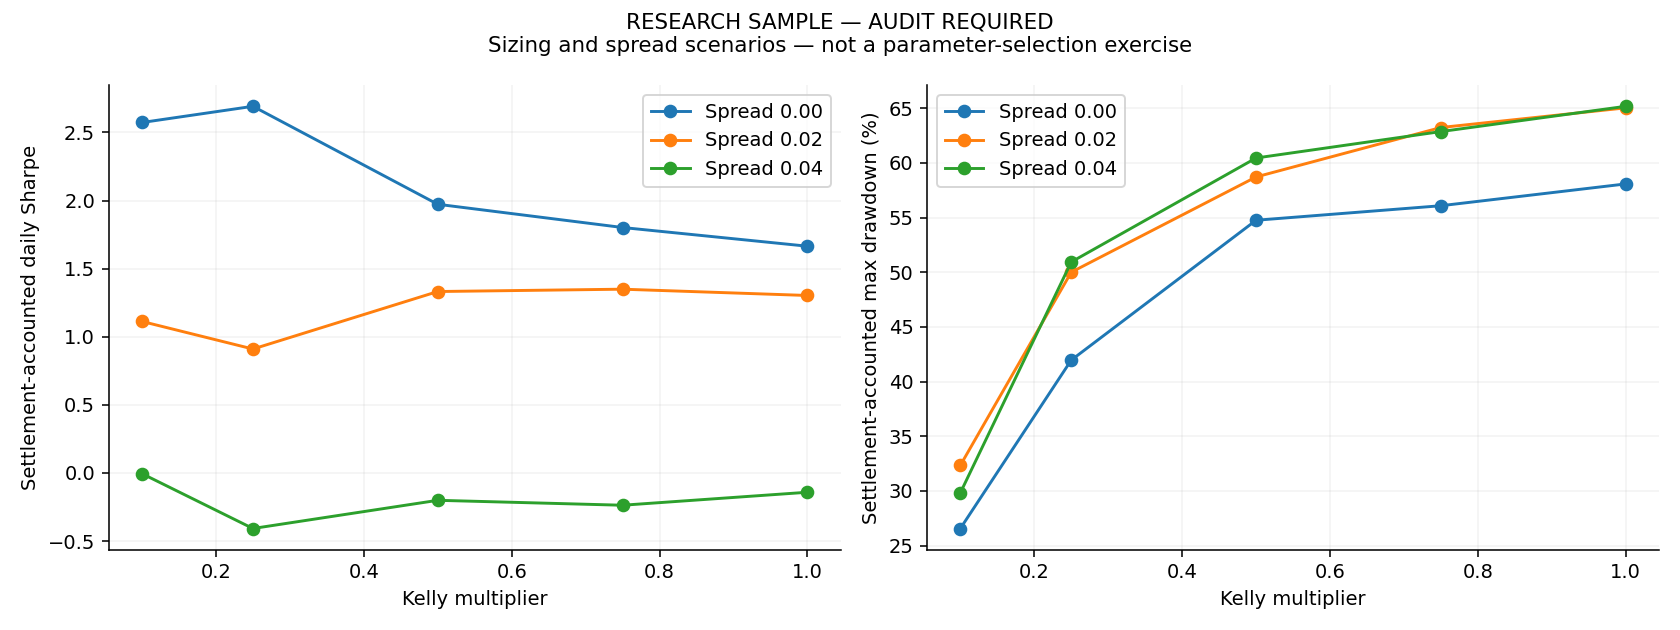

,kelly_fraction,full_spread,fee_per_contract,trades,ending_equity,total_return,settlement_max_drawdown,settlement_daily_sharpe,strategy
0,0.10,0.00,0.005,5546,20547.815,1.054781,-0.265665,2.573065,kelly
1,0.25,0.00,0.005,4641,27804.050,1.780405,-0.419656,2.691931,kelly
2,0.50,0.00,0.005,4294,22526.915,1.252692,-0.547579,1.972597,kelly
3,0.75,0.00,0.005,4156,21377.475,1.137747,-0.560857,1.802062,kelly
4,1.00,0.00,0.005,4116,20096.980,1.009698,-0.580791,1.664752,kelly
5,0.10,0.02,0.005,5049,13085.790,0.308579,-0.323416,1.112279,kelly
6,0.25,0.02,0.005,4418,13004.590,0.300459,-0.500054,0.909930,kelly
7,0.50,0.02,0.005,4007,16514.370,0.651437,-0.587171,1.332032,kelly
8,0.75,0.02,0.005,3873,16895.215,0.689522,-0.632384,1.349223,kelly
9,1.00,0.02,0.005,3816,16561.845,0.656184,-0.650360,1.303044,kelly


In [5]:
display(Image(filename=str(OUT/'calibration.png')))
display(tables['out_of_sample_calibration'])
display(pd.DataFrame([summary['baseline']]))
display(Image(filename=str(OUT/'equity.png')))
display(Image(filename=str(OUT/'sensitivity.png')))
display(tables['sensitivity'])
print('Timing, opening-time and cash-conservation checks passed during analysis.')

## What this expansion fixes—and what remains

The study now evaluates more cities, more weather dates and multiple seasons, and treats related observations more carefully. This directly addresses the original short, single-city sample.

The remaining scope is still one exchange and one daily-temperature product family, for less than a full year. Broader claims require additional years and product families. Current finalized metadata does not prove the historical clock was known at entry. Individual binary calibration also does not enforce probabilities summing to one across exhaustive temperature buckets.

After inspecting these results, freeze any next proposed model and collect a genuinely untouched future period. For a resume, emphasize the reproducible real-data pipeline, honest out-of-sample evaluation and dependence-aware inference. Do not present simulated trading performance as realized profit.

## Exploratory risk-control follow-up

After inspecting the original drawdown, we specified one-tenth Kelly and a 4% shared weather-date exposure cap. The original policy and forecasts remain unchanged. This is an exploratory comparison on already viewed data, not a new holdout test.

The middle policy isolates lower sizing. The final policy also limits aggregate entry-cost capital locked across cities for the same weather date. Exposure is released at settlement; the cap is checked before adding a position and does not force liquidation after losses. Entry ordering can affect which cities receive the limited capital. See `RISK_CONTROLS.md` for the full interpretation.

,policy,total_return,settlement_max_drawdown,ending_equity,total_capital_deployed,peak_locked_pct,peak_weather_day_at_entry_pct
0,Original quarter Kelly,0.300459,-0.500054,13004.59,769595.41,0.499978,0.239928
1,One-tenth Kelly,0.308579,-0.323416,13085.79,608001.21,0.486318,0.239829
2,One-tenth Kelly + 4% weather-day cap,0.212108,-0.161529,12121.08,119978.92,0.118500,0.040000


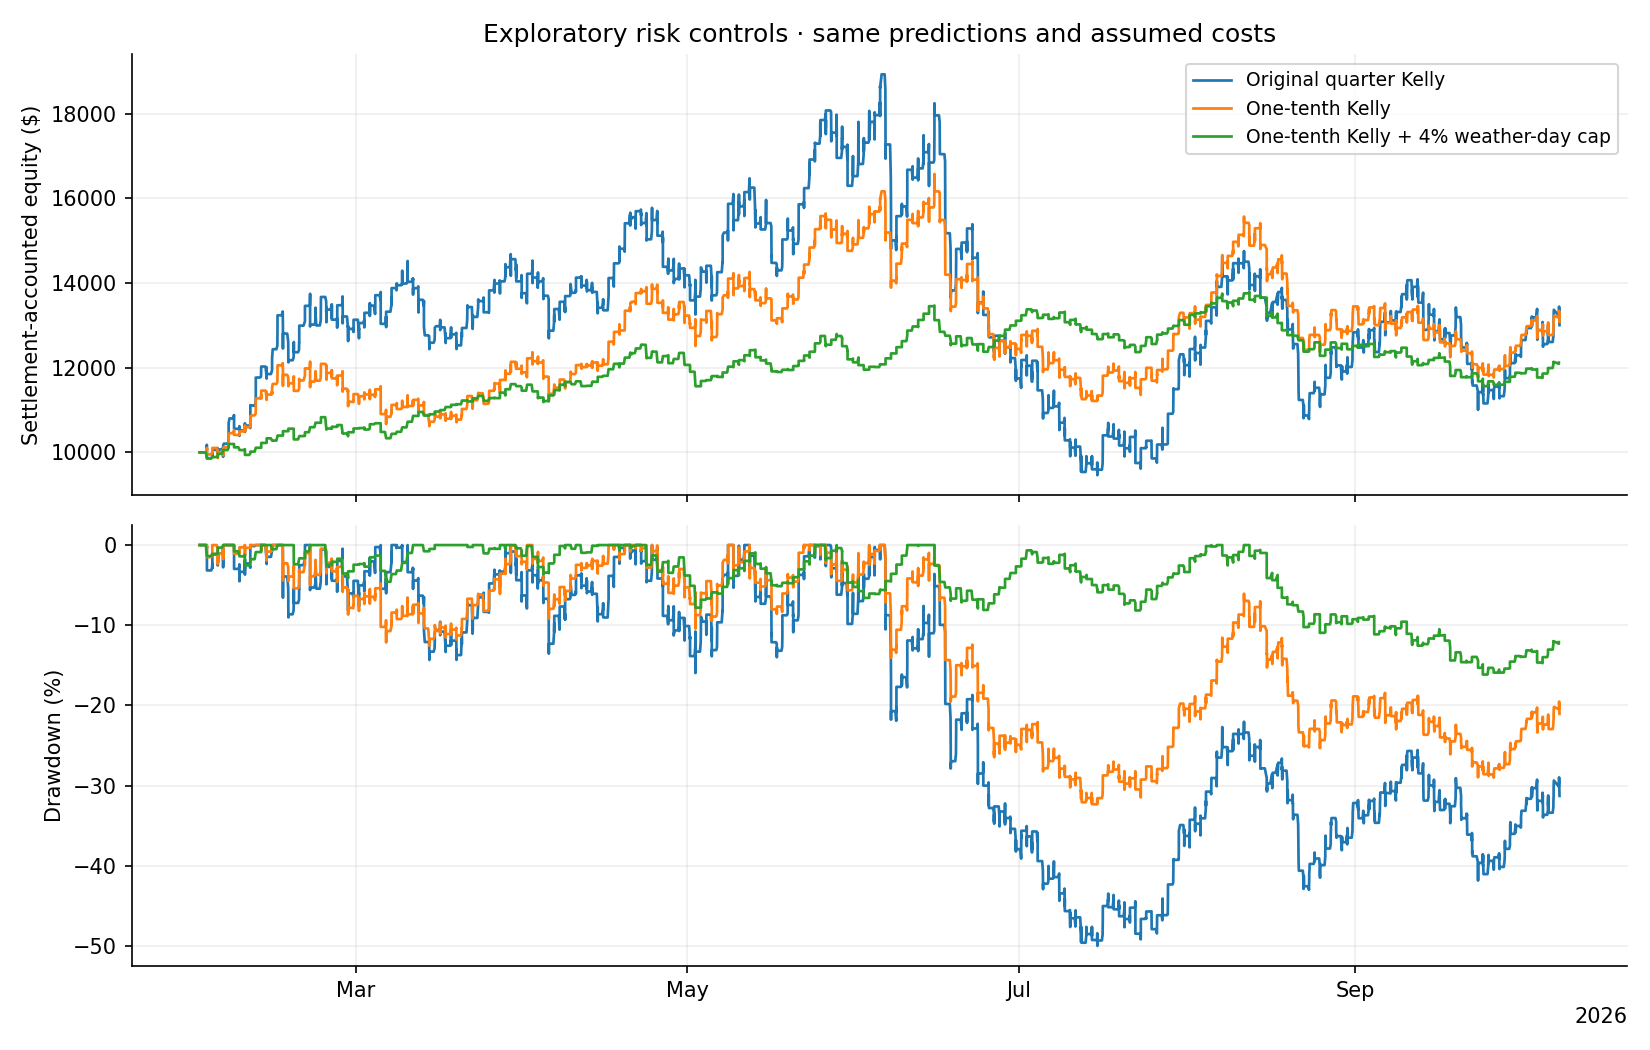

In [6]:
from risk_controls import run as run_risk_comparison
with contextlib.redirect_stdout(io.StringIO()):
    risk_results = run_risk_comparison()
display(risk_results[['policy','total_return','settlement_max_drawdown','ending_equity',
                      'total_capital_deployed','peak_locked_pct','peak_weather_day_at_entry_pct']])
display(Image(filename='outputs/risk_controls/risk_comparison.png'))